# Iris classification and LSTM time series

First part: classification of the Iris dataset with a dense network and early stopping. Second part: an LSTM that predicts daily temperatures from blocks of 10 days.

## Iris dataset

Data loaded in a pandas DataFrame, label one-hot encoded and 80/20 train/test split.

In [24]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf
import pandas as pd
from sklearn.datasets import load_iris

iris=load_iris()
df=pd.DataFrame(iris.data, columns=iris.feature_names)
#flower names as labels
df['label']=iris.target_names[iris.target]
print(df)
#sns.pairplot(df, hue='label')
#plt.show()
labelOH=pd.get_dummies(df['label'], prefix="label") #one-hot encoding
#replace the label column with the one-hot columns
df=pd.concat([df,labelOH], axis=1)
# drop old label
df.drop(['label'], axis=1, inplace=True)
print("dataframe after one hot encoding:")
print(df)

#extract random 80% of data with a fixed seed (1)
train=df.sample(frac=0.8, random_state=1)
test=df.drop(train.index)

#make x and y
x_train = train[['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']]

y_train = train[['label_setosa', 'label_versicolor', 'label_virginica']]

     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                  5.1               3.5                1.4               0.2   
1                  4.9               3.0                1.4               0.2   
2                  4.7               3.2                1.3               0.2   
3                  4.6               3.1                1.5               0.2   
4                  5.0               3.6                1.4               0.2   
..                 ...               ...                ...               ...   
145                6.7               3.0                5.2               2.3   
146                6.3               2.5                5.0               1.9   
147                6.5               3.0                5.2               2.0   
148                6.2               3.4                5.4               2.3   
149                5.9               3.0                5.1               1.8   

         label  
0       se

Dense network with a softmax output, Adam and categorical cross-entropy, 40% of the training set used for validation and early stopping on the validation loss (patience 10).

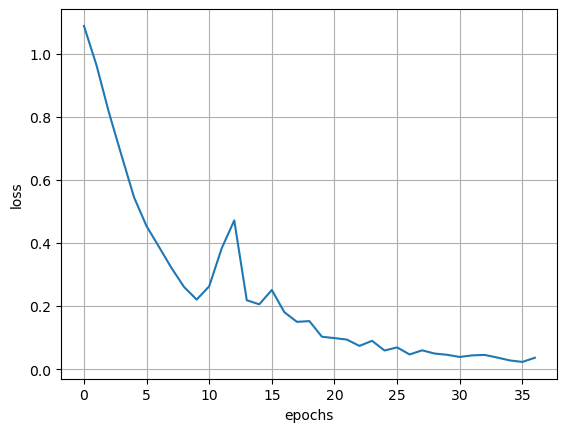

In [25]:
epochs=200

model = tf.keras.models.Sequential([
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=["accuracy"])
history=model.fit(x_train,y_train,epochs=epochs, batch_size=32, validation_split=0.4, verbose=0, 
                   callbacks=[
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10),
        tf.keras.callbacks.TensorBoard(log_dir='./log'),
    ],)

losses=history.history['loss']
N=np.arange(len(losses))

plt.plot(N,losses)
plt.grid(True)
plt.xlabel('epochs')
plt.ylabel('loss')
plt.show()

## LSTM

Daily measurements, already filtered and normalized, in blocks of 10 days (data from the course repository [scarrazza/DL2025](https://github.com/scarrazza/DL2025/tree/main/Lecture_6)). One LSTM layer with 30 units and a dense output, MSE loss, 25 epochs.

(1490, 10, 1)
(1490, 1)
(490, 10, 1)
(490, 1)
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 984us/step - accuracy: 0.0039 - loss: 0.0018   
final test loss=0.0019314554519951344
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
MSE = 0.0019314555502041146


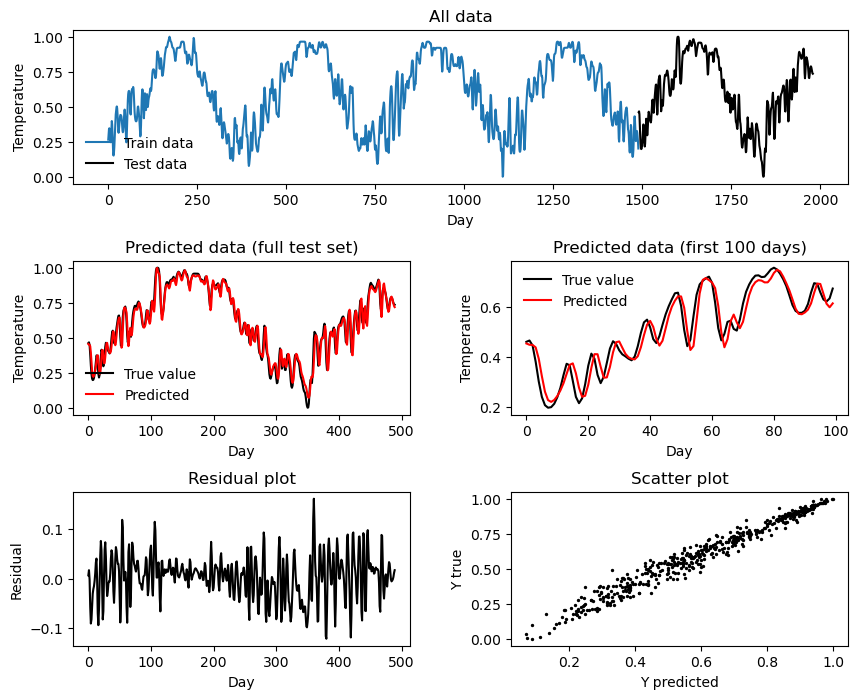

In [42]:

import numpy as np
x_train=np.load("training_data.npy")
y_train=np.load("training_label.npy")
x_test=np.load("test_data.npy")
y_test=np.load("test_label.npy")
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

#build lstm model
model=tf.keras.models.Sequential([tf.keras.layers.LSTM(30, activation='relu'),#RNN LSTM layer with 30 hidden units
                                  tf.keras.layers.Dense(1)]) #output layer
model.compile(optimizer='adam', loss='mse', metrics=['accuracy'])
epochs=25
history=model.fit(x_train, y_train, epochs=epochs, batch_size=32, verbose=0)
#test model
test=model.evaluate(x_test,y_test, return_dict=True)
print(f"final test loss={test['loss']}")

#now the plotting part
y_predicted = model.predict(x_test)


# Show results
plt.figure(figsize=(10,8))

plt.subplot(3, 1, 1)
plt.plot(y_train, label='Train data')
plt.plot(range(len(y_train), len(y_train)+len(y_test)), y_test, 'k', label='Test data')
plt.legend(frameon=False)
plt.ylabel("Temperature")
plt.xlabel("Day")
plt.title("All data")

plt.subplot(3, 2, 3)
plt.plot(y_test, color='k', label = 'True value')
plt.plot(y_predicted, color='red', label = 'Predicted')
plt.legend(frameon=False)
plt.ylabel("Temperature")
plt.xlabel("Day")
plt.title("Predicted data (full test set)")

plt.subplot(3, 2, 4)
plt.plot(y_test[0:100], color='k', label = 'True value')
plt.plot(y_predicted[0:100], color = 'red', label='Predicted')
plt.legend(frameon=False)
plt.ylabel("Temperature")
plt.xlabel("Day")
plt.title("Predicted data (first 100 days)")

plt.subplot(3, 2, 5)
plt.plot(y_test-y_predicted, color='k')
plt.ylabel("Residual")
plt.xlabel("Day")
plt.title("Residual plot")

plt.subplot(3, 2, 6)
plt.scatter(y_predicted, y_test, s=2, color='black')
plt.ylabel("Y true")
plt.xlabel("Y predicted")
plt.title("Scatter plot")

mse = np.mean(np.square(y_test - y_predicted))
print(f"MSE = {mse}")

plt.subplots_adjust(hspace = 0.5, wspace=0.3)
plt.show()